In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/paysim.csv")
print(df.shape)
df.to_parquet("../data/processed/paysim.parquet", index=False)

(6362620, 11)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_parquet("../data/processed/paysim.parquet")
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(6362620, 11)
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [4]:
print("Overall fraud rate:", df["isFraud"].mean())

by_type = df.groupby("type").agg(
    transactions=("isFraud", "size"),
    frauds=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean"),
)
by_type

Overall fraud rate: 0.001290820448180152


,transactions,frauds,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


In [7]:
total_fraud_count = df["isFraud"].sum()
total_fraud_value = df.loc[df["isFraud"] == 1, "amount"].sum()

def rule_performance(flag, name):
    flagged = df[flag]
    caught = flagged["isFraud"].sum()
    caught_value = flagged.loc[flagged["isFraud"] == 1, "amount"].sum()
    return {
        "rule": name,
        "alerts": len(flagged),
        "frauds_caught": caught,
        "precision": caught / len(flagged) if len(flagged) else 0,
        "fraud_count_caught_%": 100 * caught / total_fraud_count,
        "fraud_value_caught_%": 100 * caught_value / total_fraud_value,
    }

rules = pd.DataFrame([
    rule_performance(df["isFlaggedFraud"] == 1, "isFlaggedFraud column"),
    rule_performance((df["type"] == "TRANSFER") & (df["amount"] > 200_000), "Documented rule: TRANSFER > 200,000"),
])
rules

,rule,alerts,frauds_caught,precision,fraud_count_caught_%,fraud_value_caught_%
0,isFlaggedFraud column,16,16,1.000000,0.194813,0.645180
1,"Documented rule: TRANSFER > 200,000",409110,2740,0.006697,33.361744,49.403849


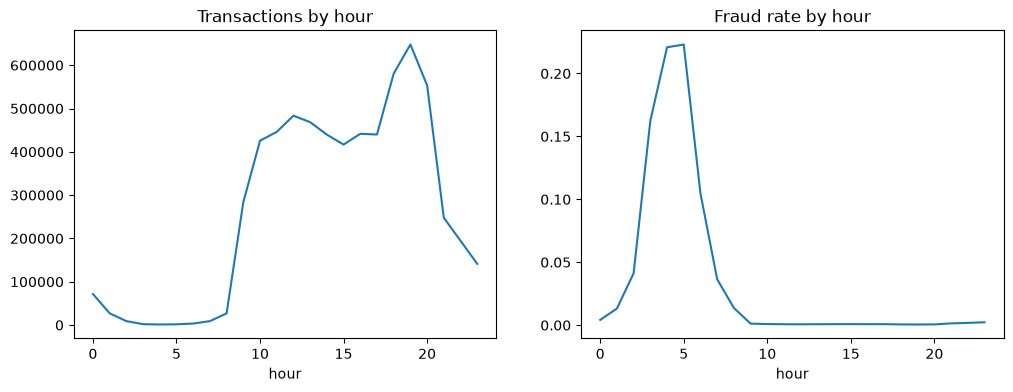

,transactions,frauds
day,,
0,571039,265
1,452761,305
2,6749,306
3,21904,272
4,12995,244
5,440626,230
6,420282,280
7,449147,270
8,418103,259


In [5]:
df["hour"] = df["step"] % 24
df["day"] = df["step"] // 24

hourly = df.groupby("hour").agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"))
hourly["fraud_rate"] = hourly["frauds"] / hourly["transactions"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hourly["transactions"].plot(ax=ax[0], title="Transactions by hour")
hourly["fraud_rate"].plot(ax=ax[1], title="Fraud rate by hour")
plt.show()

daily = df.groupby("day").agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"))
daily

In [6]:
fraud = df[df["isFraud"] == 1]

transfer_dest = set(fraud.loc[fraud["type"] == "TRANSFER", "nameDest"])
cashout_orig = set(fraud.loc[fraud["type"] == "CASH_OUT", "nameOrig"])
print("Fraud TRANSFER destinations that later originate a fraud CASH_OUT:",
      len(transfer_dest & cashout_orig))

print("Unique nameOrig share:", df["nameOrig"].nunique() / len(df))
print("Unique nameDest share:", df["nameDest"].nunique() / len(df))

print(fraud["nameDest"].value_counts().head(10))

Fraud TRANSFER destinations that later originate a fraud CASH_OUT: 0
Unique nameOrig share: 0.9985362947967975
Unique nameDest share: 0.4278680795018404
nameDest
C410033330     2
C803116137     2
C904300960     2
C1013511446    2
C2020337583    2
C200064275     2
C185805228     2
C52390890      2
C935310781     2
C1827219533    2
Name: count, dtype: int64
